# Chapitre 8 - Cours 5 : fautes byzantines, modèles de système et correction

Jusqu'ici, les nœuds étaient lents, absents ou mal informés, mais **honnêtes**. Que se
passe-t-il s'ils peuvent mentir ? Et comment raisonner rigoureusement sur un algorithme
quand tout peut défaillir ? Ce notebook traite des fautes **byzantines**, des **modèles
de système** (hypothèses explicites sur ce qui peut mal tourner) et de la définition de
la **correction** d'un algorithme distribué par des propriétés de **sûreté** et de
**vivacité**. Il couvre la fin de *Knowledge, Truth, and Lies* : *Byzantine Faults*
(encadré *The Byzantine Generals Problem*, *Weak forms of lying*) et *System Model and
Reality* (*Correctness of an algorithm*, *Safety and liveness*, *Mapping system models to
the real world*).

**Plan.**

1. Fautes byzantines et problème des généraux.
2. Quand faut-il tolérer les fautes byzantines ?
3. Les formes faibles de mensonge.
4. Modèles de système.
5. Correction d'un algorithme : sûreté et vivacité.
6. Des modèles au monde réel.

In [1]:
import itertools
from math import comb, prod

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Fautes byzantines et problème des généraux (section *Byzantine Faults*)

Les jetons de clôture du cours 4 bloquent un nœud qui se trompe **de bonne foi** (il ne
sait pas encore que son bail a expiré). Mais un nœud qui voudrait **délibérément**
subvertir le système n'aurait qu'à envoyer un faux jeton. Le livre suppose que les nœuds
sont **non fiables mais honnêtes** : lents, muets, mal informés (pause, délai réseau),
mais s'ils répondent, ils disent « la vérité » telle qu'ils la connaissent et respectent
le protocole. Un nœud qui peut **mentir** (réponses arbitrairement fausses, votes
contradictoires dans une même élection) commet une **faute byzantine** ; trouver un
consensus dans ces conditions est le **problème des généraux byzantins**.

**Les deux généraux** (encadré *The Byzantine Generals Problem*). Deux généraux, campés à
des endroits différents, doivent s'accorder sur un plan d'attaque ; ils ne communiquent
que par messagers, qui peuvent être retardés ou capturés, comme les paquets d'un réseau.

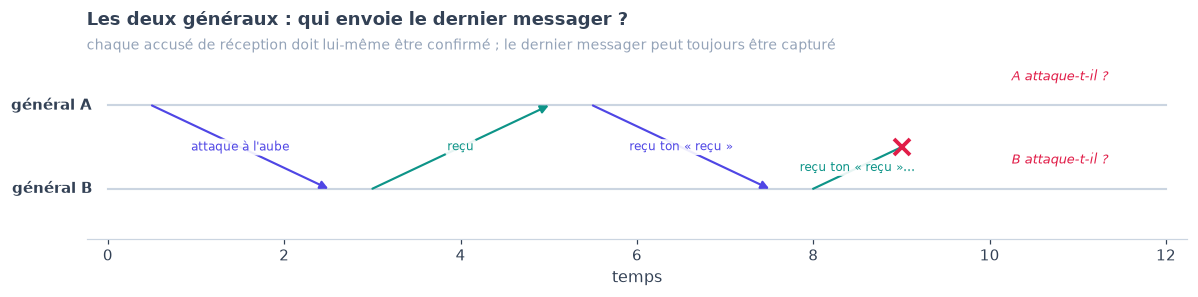

In [2]:
st = SpaceTime(["général A", "général B"], t_max=12, width=11, title="Les deux généraux : qui envoie le dernier messager ?",
               subtitle="chaque accusé de réception doit lui-même être confirmé ; le dernier messager peut toujours être capturé")
st.msg("général A", 0.5, "général B", 2.5, "attaque à l'aube", color=INDIGO)
st.msg("général B", 3.0, "général A", 5.0, "reçu", color=TEAL)
st.msg("général A", 5.5, "général B", 7.5, "reçu ton « reçu »", color=INDIGO)
st.msg("général B", 8.0, "général A", 10.0, "reçu ton « reçu »...", color=TEAL, lost=True)
st.note(10.8, "général B", "B attaque-t-il ?", dy=0.35, color=ROSE)
st.note(10.8, "général A", "A attaque-t-il ?", dy=0.35, color=ROSE)
st.show()

Aucun nombre fini de messages ne suffit : celui qui envoie le dernier ne sait pas s'il
est arrivé, et l'autre le sait. Le chapitre 9 reviendra sur ce problème
de consensus. Dans la version **byzantine**, $n$ généraux doivent s'accorder alors que
certains sont des **traîtres**, inconnus, qui envoient des messages faux pour semer la
confusion. (Byzance, devenue Constantinople puis Istanbul, n'avait pas de généraux plus
fourbes qu'ailleurs : le nom vient de l'adjectif « byzantin », compliqué et tortueux ;
Lamport cherchait une nationalité qui ne vexerait personne.)

**L'algorithme OM(m)** de Lamport, Shostak et Pease (1982, « oral messages ») résout le
problème avec $m$ traîtres : le commandant envoie un ordre à chaque lieutenant ; chaque
lieutenant relaie ce qu'il a reçu aux autres (récursivement, OM(m-1)) ; chacun décide à la
**majorité** des valeurs reçues. Il faut garantir :

- **IC1** : tous les lieutenants loyaux prennent la même décision ;
- **IC2** : si le commandant est loyal, ils exécutent son ordre.

`ds.byzantine_check` exécute OM(m) contre des traîtres qui mentent de **toutes** les
façons possibles (chaque message d'un traître peut valoir 0 ou 1, selon le destinataire et
le chemin), ou contre un échantillon de stratégies quand elles sont trop nombreuses.

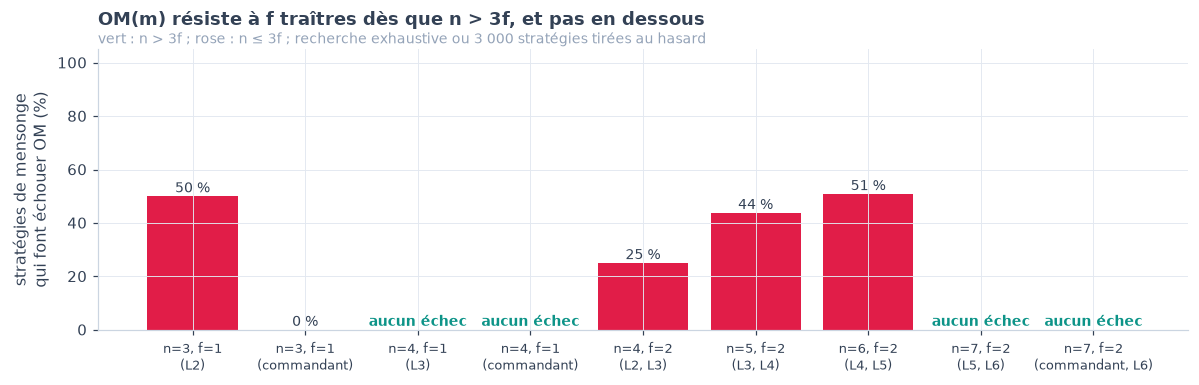

,n,m,traîtres,f,n > 3f ?,stratégies,échecs
0,3,1,L2,1,False,2,1
1,3,1,commandant,1,False,4,0
2,4,1,L3,1,True,4,0
3,4,1,commandant,1,True,8,0
4,4,1,"L2, L3",2,False,16,4
5,5,1,"L3, L4",2,False,64,28
6,6,2,"L4, L5",2,False,3000,1525
7,7,2,"L5, L6",2,True,3000,0
8,7,2,"commandant, L6",2,True,3000,0


In [3]:
cas = [(3, 1, {2}), (3, 1, {0}), (4, 1, {3}), (4, 1, {0}), (4, 1, {2, 3}), (5, 1, {3, 4}),
       (6, 2, {4, 5}), (7, 2, {5, 6}), (7, 2, {0, 6})]
rows = []
for n, m, tr in cas:
    r = ds.byzantine_check(n, m, tr, n_strategies=3000, seed=1)
    rows.append(dict(n=n, m=m, traîtres=", ".join("commandant" if t == 0 else f"L{t}" for t in sorted(tr)),
                     f=len(tr), **{"n > 3f ?": n > 3 * len(tr)}, stratégies=r["strategies"],
                     échecs=r["echecs"], exemple=r["exemple"]))
B = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(11, 3.6))
lab = [f"n={r.n}, f={r.f}\n({r.traîtres})" for r in B.itertuples()]
taux = B.échecs / B.stratégies * 100
ax.bar(range(len(B)), taux, color=[TEAL if ok else ROSE for ok in B["n > 3f ?"]])
for i, (v, ok) in enumerate(zip(taux, B["n > 3f ?"])):
    ax.text(i, v + 1.5, f"{v:.0f} %" if v or not ok else "aucun échec", ha="center", fontsize=9,
            color=TEAL if ok else SLATE, fontweight="bold" if ok else None)
ax.set_xticks(range(len(B))); ax.set_xticklabels(lab, fontsize=8.5)
ax.set_ylabel("stratégies de mensonge\nqui font échouer OM (%)"); ax.set_ylim(0, 105)
ax.set_title("OM(m) résiste à f traîtres dès que n > 3f, et pas en dessous")
subtitle(ax, "vert : n > 3f ; rose : n ≤ 3f ; recherche exhaustive ou 3 000 stratégies tirées au hasard")
plt.tight_layout(); plt.show()
B.drop(columns="exemple")

Le résultat illustre le théorème : avec $f$ traîtres, il faut **plus de $3f$ généraux**
(plus des deux tiers loyaux). Avec 3 généraux et un lieutenant traître, une stratégie
sur deux suffit à tromper le lieutenant loyal : il reçoit « attaque » du commandant et
« le commandant a dit retraite » du traître, et ne peut pas savoir qui ment (il choisit
alors la valeur par défaut, contraire à l'ordre du commandant loyal). Avec 3 généraux et
un commandant traître, OM(1) s'en sort ici par chance (les deux lieutenants, à égalité,
choisissent la même valeur par défaut) : l'impossibilité porte sur le pire cas, et il
suffit qu'**une** position de traître fasse échouer l'algorithme. Avec 4 généraux,
aucune des stratégies ne fait échouer OM(1) ; avec 7 généraux et 2 traîtres, aucune des
3 000 stratégies tirées n'y parvient, alors qu'avec 6 elles réussissent souvent.

Le prix est élevé : OM(m) envoie $\sum_{k=1}^{m+1} \prod_{i=1}^{k}(n-i)$ messages, soit
de l'ordre de $n^{m+1}$.

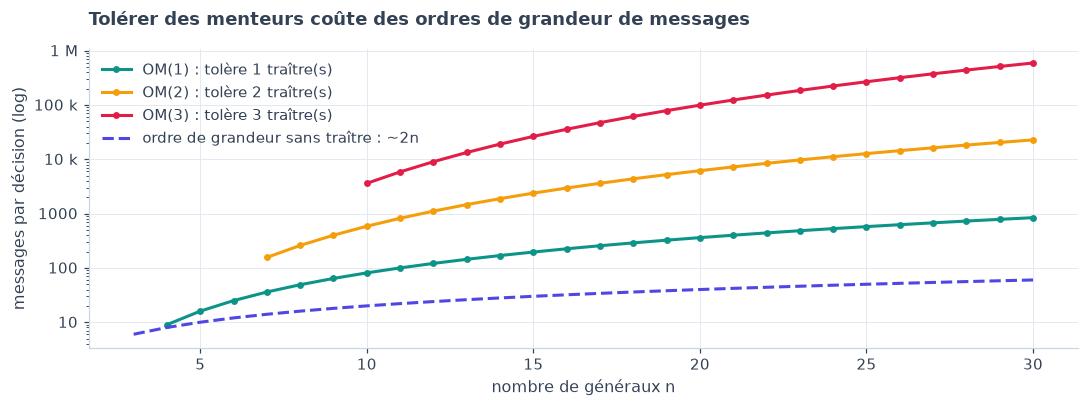

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for m, c in [(1, TEAL), (2, AMBER), (3, ROSE)]:
    ns = np.arange(3 * m + 1, 31)
    msgs = [sum(prod(n - i for i in range(1, k + 1)) for k in range(1, m + 2)) for n in ns]
    ax.semilogy(ns, msgs, "o-", ms=3.5, color=c, label=f"OM({m}) : tolère {m} traître(s)")
ax.semilogy(np.arange(3, 31), 2 * np.arange(3, 31), "--", color=INDIGO, label="ordre de grandeur sans traître : ~2n")
plain_log_axis(ax, "y")
ax.set_xlabel("nombre de généraux n"); ax.set_ylabel("messages par décision (log)")
ax.set_title("Tolérer des menteurs coûte des ordres de grandeur de messages")
ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** Une faute byzantine est un nœud qui ment. Atteindre un accord malgré $f$
> menteurs exige plus de $3f$ nœuds (contre $2f+1$ pour des pannes franches) et beaucoup
> plus de messages.

## 2. Quand faut-il tolérer les fautes byzantines ? (section *Byzantine Faults*)

Un système **tolérant aux fautes byzantines** continue de fonctionner correctement même si
certains nœuds n'obéissent pas au protocole ou si des attaquants interfèrent avec le
réseau. C'est nécessaire dans quelques contextes :

- **aérospatial** : un rayonnement peut corrompre la mémoire ou un registre et faire
  répondre un calculateur de façon arbitraire ; une défaillance coûterait des vies, donc
  les commandes de vol doivent tolérer ces fautes ;
- systèmes à **plusieurs parties qui se méfient** les unes des autres : les mécanismes de
  consensus des cryptomonnaies comme Bitcoin et des chaînes de blocs permettent à des
  parties sans confiance mutuelle de s'accorder sur une transaction sans autorité centrale.

Dans les systèmes du livre, on peut généralement **supposer qu'il n'y en a pas** : dans
un centre de données, tous les nœuds appartiennent à la même organisation et le
rayonnement est assez faible. Les clients d'un système multi-locataire se méfient les uns
des autres, mais on les isole par pare-feu, virtualisation et contrôle d'accès, pas par
des protocoles byzantins, trop coûteux (section 1). Une application web doit s'attendre à
des comportements arbitraires et malveillants des **clients** (navigateurs) : c'est le
rôle de la validation des entrées, de l'échappement (injection SQL, script intersite),
mais le serveur reste l'**autorité** ; dans un réseau pair-à-pair sans autorité centrale,
la tolérance byzantine redevient pertinente.

**Contre les bogues et les attaques, elle n'aide pas.** Un bogue logiciel est une faute
byzantine, mais si tous les nœuds exécutent le même logiciel, tous l'ont : un algorithme
byzantin ne sauve rien. Il faudrait (avec $n = 4$ pour $f = 1$) **quatre implémentations
indépendantes** et espérer qu'un bogue donné n'en touche qu'une. De même, un attaquant
qui compromet un nœud peut probablement compromettre tous les autres, qui font tourner le
même logiciel : authentification, contrôle d'accès, chiffrement et pare-feu restent les
protections principales.

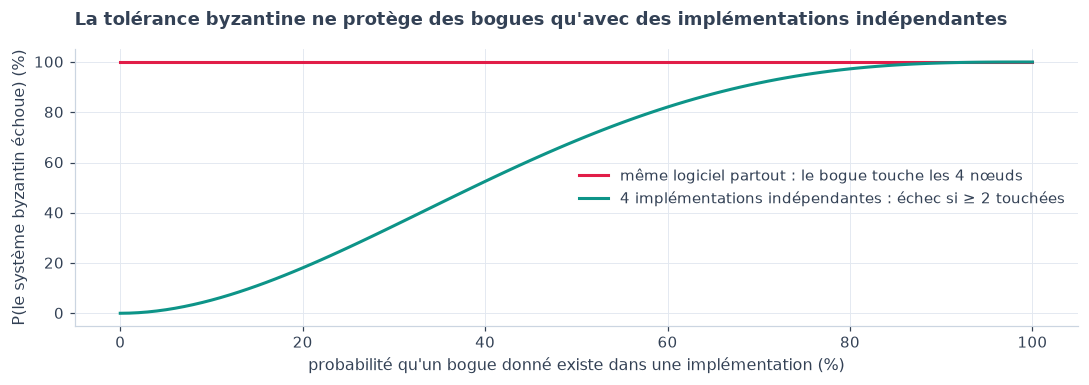

In [5]:
q_bug = np.linspace(0, 1, 101)       # probabilité qu'un bogue donné touche une implémentation
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(q_bug * 100, 100 * np.ones_like(q_bug), color=ROSE, label="même logiciel partout : le bogue touche les 4 nœuds")
p_fail = 1 - ((1 - q_bug) ** 4 + 4 * q_bug * (1 - q_bug) ** 3)          # au moins 2 sur 4 touchées
ax.plot(q_bug * 100, p_fail * 100, color=TEAL, label="4 implémentations indépendantes : échec si ≥ 2 touchées")
ax.set_xlabel("probabilité qu'un bogue donné existe dans une implémentation (%)")
ax.set_ylabel("P(le système byzantin échoue) (%)")
ax.set_title("La tolérance byzantine ne protège des bogues qu'avec des implémentations indépendantes")
ax.legend(loc="center right")
plt.tight_layout(); plt.show()

> **À retenir.** La tolérance byzantine sert quand des parties se méfient les unes des
> autres ou quand le matériel peut corrompre les calculs (aérospatial, chaînes de blocs).
> Dans un centre de données, on suppose les nœuds honnêtes : elle coûte trop cher et ne
> protège ni des bogues communs ni des attaquants.